In [4]:
import importlib.util
import sys
import subprocess

def check_and_install(package_name):
    # Check if the package is installed
    spec = importlib.util.find_spec(package_name)
    
    if spec is None:
        # Install if it is not found
        print(f" '{package_name}' not found. Installing now...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
    else:
        print(f" '{package_name}' is already installed.")

check_and_install("numpy")
check_and_install("matplotlib")
check_and_install("cmasher")
check_and_install("astropy")
check_and_install("scipy")

 'numpy' is already installed.
 'matplotlib' is already installed.
 'cmasher' is already installed.
 'astropy' is already installed.
 'scipy' is already installed.


In [5]:
# import libraries
from math import log10, floor
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colours
import cmasher as cm
from astropy.io import ascii, fits
from astropy.table import Table, join
from scipy.odr import *

C:\Users\User\AppData\Local\Temp\ipykernel_19624\875286273.py:9: DeprecationWarning: `scipy.odr` is deprecated as of version 1.17.0 and will be removed in SciPy 1.19.0. Please use `https://pypi.org/project/odrpack/` instead.
  from scipy.odr import *


In [15]:
# import the csv file
# here we put the name of the file as a string
# the delimiter is what separate the different data
# skiprow tells the function how many rows to skip from the start of the file
# dtype sets the type of object being imported
vandenBerg_data = np.loadtxt('vandenBerg_table2.csv', delimiter= ',', skiprows=1, dtype=object)

# store each column as a new variable
Id_name = vandenBerg_data[:,0]
star_name = vandenBerg_data[:,1]
FeH = vandenBerg_data[:,2].astype(float) 
Age = vandenBerg_data[:,3].astype(float)

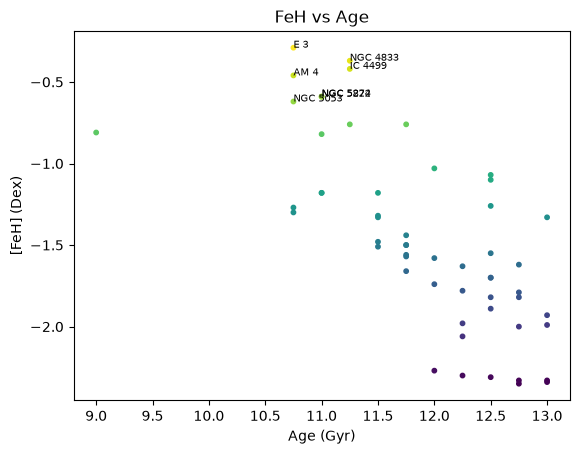

In [54]:
plt.scatter(Age, FeH, c=FeH, marker='o', s=10)

# Axes
plt.title('FeH vs Age') # Title of graph
plt.xlabel('Age (Gyr)') # x-axis label
plt.ylabel('[FeH] (Dex)') # y-axis label

# select unusual points for closer inspection
outliers = FeH > -0.7
for i in range(len(FeH)):
    if outliers[i]:
        plt.annotate(str(Id_name[i]), (Age[i], FeH[i]), fontsize=7)


- Many older clusters have low metallicities, with [Fe/H] around -1.5 to -2.3
- Some clusters approximately 10.7 - 11.3 Gyr have higher metallicities, around -0.3 to 0.7
- The sample has a broad distribution rather than one tight age metallicity relationship
- The points to examine: E3, AM4, NGC 4833, NGC4499, NGC5828, NGC5053

In [26]:
HarrisPartIII_data = np.loadtxt('HarrisPartIII.csv', delimiter= ',', skiprows=1, dtype=object)

# store each column as a new variable
Id_name = HarrisPartIII_data[:,0]
v_LSR = HarrisPartIII_data[:,3]

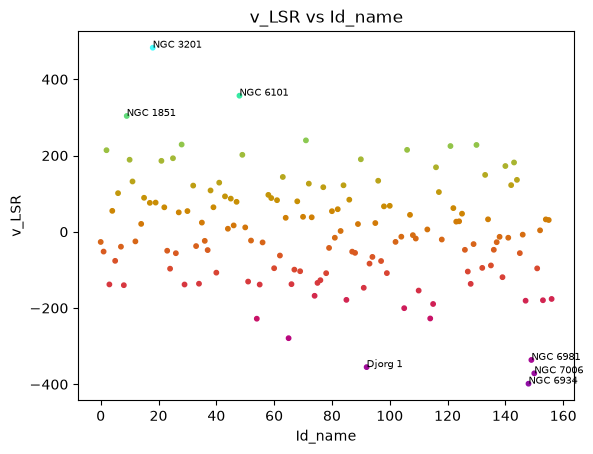

In [50]:
cmap = colours.ListedColormap(['#ff6347', '#fe8951', '#ffa93e', '#ffc728', '#ffe410', '#90b2e8', '#778ce5', '#5d66df', '#403ed7', '#0000cd'])
cmap_2 = cm.tropical

v_LSR_numeric = np.array([float(value) if value else np.nan for value in v_LSR])
valid = ~np.isnan(v_LSR_numeric)

plt.scatter(np.arange(len(Id_name))[valid], v_LSR_numeric[valid], c=v_LSR_numeric[valid], marker='o', s=10, cmap=cmap_2)

# Axes
plt.title('v_LSR vs Id_name') # Title of graph
plt.xlabel('Id_name') # x-axis label
plt.ylabel('v_LSR') # y-axis label

for i in range(len(Id_name)):
    if valid[i] and abs(v_LSR_numeric[i]) > 300:
        plt.annotate(str(Id_name[i]), (np.arange(len(Id_name))[i], v_LSR_numeric[i]), fontsize=7)

- It makes unusually large positiove and negative velocities easy to spot.
- points to examine: NGC3201, NGC6101, NGC6981, NGC7006, IC6934, Djorg1

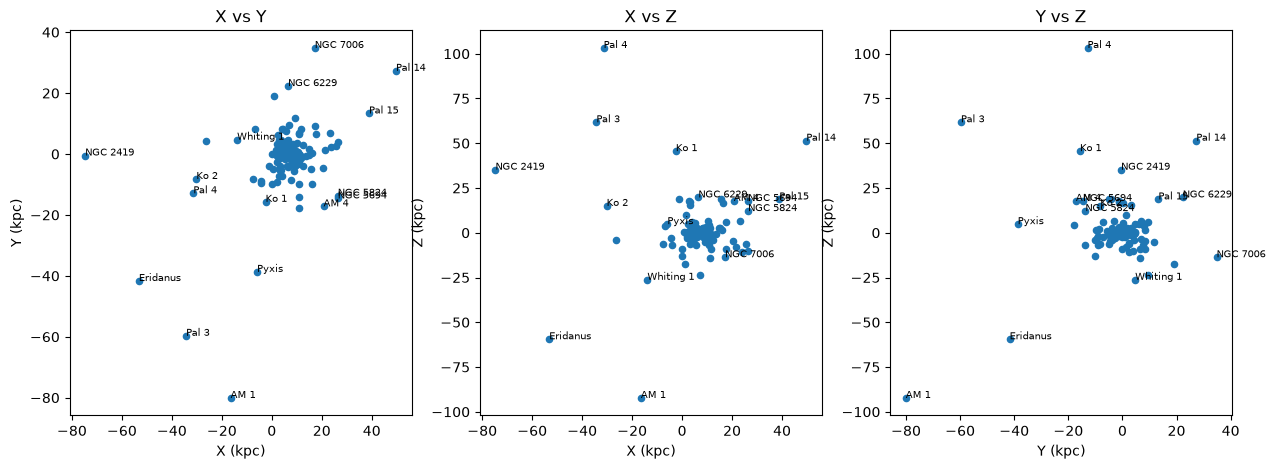

In [52]:
gc = ascii.read('HarrisPartI.csv')

gc_x = gc['X']
gc_y = gc['Y']
gc_z = gc['Z']
gc_L = gc['L']
gc_Id = gc['ID']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

xy = axes[0].scatter(gc_x, gc_y, marker='o', s=20)
axes[0].set_xlabel('X (kpc)')
axes[0].set_ylabel('Y (kpc)')
axes[0].set_title('X vs Y')

xy = axes[1].scatter(gc_x, gc_z, marker='o', s=20)
axes[1].set_xlabel('X (kpc)')
axes[1].set_ylabel('Z (kpc)')
axes[1].set_title('X vs Z')

xy = axes[2].scatter(gc_y, gc_z, marker='o', s=20)
axes[2].set_xlabel('Y (kpc)')
axes[2].set_ylabel('Z (kpc)')
axes[2].set_title('Y vs Z')

for i in range(len(gc_x)):
    r = np.sqrt(gc_x[i]**2 + gc_y[i]**2 + gc_z[i]**2)

    if r > 30:
        axes[0].annotate(str(gc_Id[i]), (gc_x[i], gc_y[i]), fontsize=7)
        axes[1].annotate(str(gc_Id[i]), (gc_x[i], gc_z[i]), fontsize=7)
        axes[2].annotate(str(gc_Id[i]), (gc_y[i], gc_z[i]), fontsize=7)

- Most points are concentrated near the central region of the plotted coordinate system
- Some clusters lie much farther away and to be examine: Pal3, Pal4, Pal14, Pal15, AM1, Eridanus, Pyxis, NGC2419, NGC7006

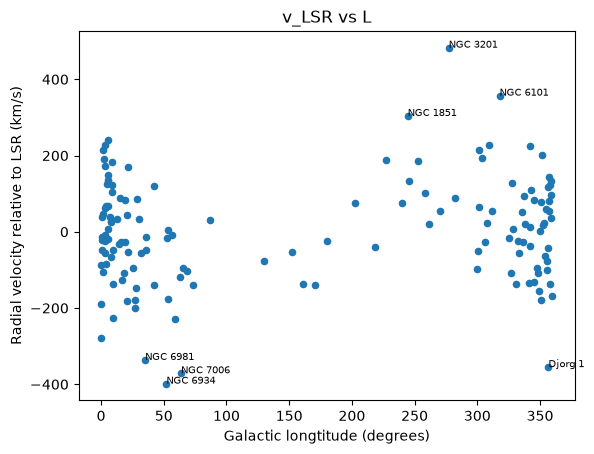

In [55]:
plt.scatter(gc_L, v_LSR_numeric, s=20)
plt.xlabel('Galactic longtitude (degrees)')
plt.ylabel('Radial velocity relative to LSR (km/s)')
plt.title('v_LSR vs L')

#outliers
outliers = np.abs(v_LSR_numeric) > 300
for i in range(len(v_LSR_numeric)):
    if outliers[i]:
        plt.annotate(str(gc_Id[i]), (gc_L[i], v_LSR_numeric[i]), fontsize=7)

The velocities span a wide range, approximately -400 to +480 km/s
- some labbeled clusters have unusually large positive or negative radial velocities: NGC3201, NGC1851, NGC6101, NGC6981, NGC7006, IC6934 and Djorg1